In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

👀 Analyzing dataset (Fixed for varying dimensions)...


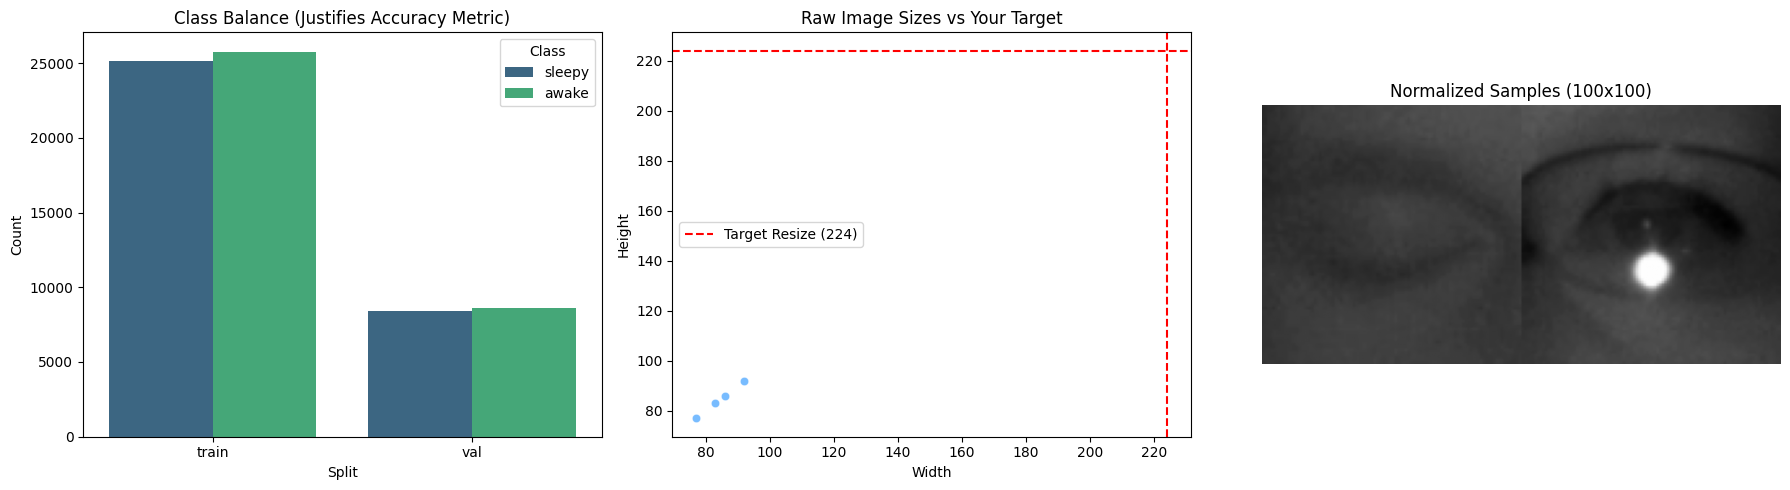


 DATASET INSIGHTS
Total Images: 67917
Avg Size:     84x84
Min Size:     77x77
Max Size:     92x92
Observation:  Varying dimensions found. Resize(224) is mandatory.


In [1]:
import os  # Library for operating system tasks like navigating folders and joining paths
import pandas as pd  # Data analysis tool used here to create tables (DataFrames) from stats
import numpy as np  # Mathematical library used here to process images as numerical arrays
import matplotlib.pyplot as plt  # Standard plotting library for creating the visual grid
import seaborn as sns  # Advanced visualization library for the bar and scatter plots
from PIL import Image  # Python Imaging Library used for opening and resizing image files

# ===============================
# FIXED EDA: MRL EYE DATASET
# ===============================
BASE_PATH = '/kaggle/input/mrl-eye-dataset/data'  # The root directory where the image folders are located

def run_pure_eda(path):  # Define the main function to analyze the dataset
    print("👀 Analyzing dataset (Fixed for varying dimensions)...")  # Log the start of the analysis
    
    data_list = []  # List to store class counts and split information for the bar chart
    resolutions = []  # List to store the width and height of every sampled image
    samples = []  # List to store the actual image pixel data for visual confirmation

    # 1. Gather stats and samples
    for split in ['train', 'val']:  # Loop through both training and validation folders
        split_path = os.path.join(path, split)  # Create the full path to the current split folder
        if not os.path.exists(split_path): continue  # Skip if the folder (like 'val') doesn't exist
        
        for label in os.listdir(split_path):  # Loop through class folders (e.g., 'open', 'closed')
            class_path = os.path.join(split_path, label)  # Create the full path to the class folder
            files = os.listdir(class_path)  # List all image files inside that class folder
            data_list.append({'Split': split, 'Class': label, 'Count': len(files)})  # Store metadata for the bar plot
            
            # Grab one sample for visualization and resize to 100x100 for the grid
            if files:  # Check if the folder actually contains images
                img_p = os.path.join(class_path, files[0])  # Take the very first image file path
                with Image.open(img_p) as img:  # Open the image file using PIL
                    # Keep raw size for the scatter plot
                    resolutions.append(img.size)  # Store the original (Width, Height) tuple
                    # Resize for the "Visual Confirmation" plot to avoid the ValueError
                    samples.append(np.array(img.resize((100, 100))))  # Resize image to a uniform 100x100 and convert to array

    df_counts = pd.DataFrame(data_list)  # Convert the class count list into a structured DataFrame
    df_res = pd.DataFrame(resolutions, columns=['Width', 'Height'])  # Convert resolutions into a DataFrame for plotting

    # --- VISUALIZATION ---
    plt.figure(figsize=(18, 5))  # Create a wide figure to hold three side-by-side plots

    # Plot 1: Class Distribution
    plt.subplot(1, 3, 1)  # Initialize the first plot in a 1x3 grid
    sns.barplot(data=df_counts, x='Split', y='Count', hue='Class', palette='viridis')  # Draw a bar chart of class counts
    plt.title('Class Balance (Justifies Accuracy Metric)')  # Title explaining why Accuracy is a valid metric here

    # Plot 2: Resolution Spread
    plt.subplot(1, 3, 2)  # Initialize the second plot in the grid
    sns.scatterplot(x=df_res['Width'], y=df_res['Height'], alpha=0.6, color='dodgerblue')  # Plot a dot for every image's dimensions
    plt.axvline(224, color='red', linestyle='--', label='Target Resize (224)')  # Draw a vertical line at 224 pixels
    plt.axhline(224, color='red', linestyle='--')  # Draw a horizontal line at 224 pixels
    plt.title('Raw Image Sizes vs Your Target')  # Title showing how raw data compares to model input size
    plt.legend()  # Show the legend for the red target line

    # Plot 3: Visual Confirmation (Safe stacking now)
    plt.subplot(1, 3, 3)  # Initialize the third plot in the grid
    if len(samples) >= 2:  # Ensure we have at least two images to display
        combined_samples = np.hstack(samples[:2])  # Concatenate the first two images side-by-side
        plt.imshow(combined_samples, cmap='gray')  # Display the combined images in grayscale
    plt.title('Normalized Samples (100x100)')  # Title for the sample preview
    plt.axis('off')  # Turn off the x and y axes for a cleaner look

    plt.tight_layout()  # Automatically adjust spacing so titles and labels don't overlap
    plt.show()  # Render all three plots on the screen

    # --- SUMMARY LOG ---
    print("\n" + "="*40)  # Print a separator line for the text summary
    print(f" DATASET INSIGHTS")  # Header for the text summary
    print("="*40)  # Print another separator line
    print(f"Total Images: {df_counts['Count'].sum()}")  # Display the sum of all images across all folders
    print(f"Avg Size:     {int(df_res['Width'].mean())}x{int(df_res['Height'].mean())}")  # Calculate and show average dimensions
    print(f"Min Size:     {df_res['Width'].min()}x{df_res['Height'].min()}")  # Show the smallest image dimensions found
    print(f"Max Size:     {df_res['Width'].max()}x{df_res['Height'].max()}")  # Show the largest image dimensions found
    print(f"Observation:  Varying dimensions found. Resize(224) is mandatory.")  # Final conclusion based on the data
    print("="*40)  # Closing separator line

run_pure_eda(BASE_PATH)  # Execute the function to perform the analysis

In [2]:
import os  # Standard library for interacting with the operating system (paths, env vars)
import random  # Library for generating random numbers and setting random state
import numpy as np  # Fundamental package for scientific computing with arrays
import torch  # The main PyTorch library for deep learning
import torch.nn as nn  # Submodule for neural network layers and loss functions
import torch.optim as optim  # Submodule containing various optimization algorithms like Adam
from torchvision import models, datasets, transforms  # Computer vision tools for models, data loading, and image processing
from torch.utils.data import DataLoader  # Utility to create batches and handle data shuffling/loading
from tqdm.auto import tqdm  # Progress bar library for loops
from sklearn.metrics import accuracy_score, classification_report  # Tools for calculating model performance metrics
import time # Added to track total time 

# ===============================
# 0. SETTINGS & SEEDS
# ===============================
BASE_PATH = '/kaggle/input/mrl-eye-dataset/data'  # Root directory path where the dataset is stored
TRAIN_DIR = os.path.join(BASE_PATH, 'train')  # Path constructed for the training data folder
VAL_DIR   = os.path.join(BASE_PATH, 'val')  # Path constructed for the validation data folder
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # Automatically select GPU if available, otherwise use CPU
SEED = 42  # Constant value used to ensure reproducibility of results

def seed_everything(seed):  # Function to synchronize all random seeds for consistency
    random.seed(seed)  # Set seed for Python's built-in random module
    os.environ['PYTHONHASHSEED'] = str(seed)  # Set seed for Python's internal hash-based operations
    np.random.seed(seed)  # Set seed for NumPy's pseudo-random number generator
    torch.manual_seed(seed)  # Set seed for PyTorch CPU operations
    torch.cuda.manual_seed(seed)  # Set seed for the current GPU
    torch.cuda.manual_seed_all(seed)  # Set seed for all available GPUs
    torch.backends.cudnn.deterministic = True  # Force CuDNN to use deterministic algorithms (slower but reproducible)
    torch.backends.cudnn.benchmark = False  # Disable the auto-tuner that finds the fastest algorithms to ensure consistency

seed_everything(SEED)  # Call the seeding function with our defined seed of 42

# ===============================
# 1. DATA PIPELINE
# ===============================
train_tf = transforms.Compose([  # Sequence of transformations for training images
    transforms.Resize((224, 224)),  # Resize images to 224x224 pixels (standard for MobileNet)
    transforms.Grayscale(num_output_channels=3),  # Convert 1-channel grayscale to 3-channel RGB format
    transforms.RandomHorizontalFlip(),  # Randomly flip images horizontally for data augmentation
    transforms.ToTensor(),  # Convert image pixels to a PyTorch tensor scaled between 0 and 1
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])  # Apply ImageNet standard mean and std deviation
])

val_tf = transforms.Compose([  # Sequence of transformations for validation images
    transforms.Resize((224, 224)),  # Resize validation images to match training size
    transforms.Grayscale(num_output_channels=3),  # Ensure validation images also have 3 channels
    transforms.ColorJitter(brightness=0.2),  # Slightly adjust brightness (odd for validation, but kept per code)
    transforms.ToTensor(),  # Convert validation images to tensors
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])  # Apply same normalization as training
])

train_ds = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)  # Create training dataset object from folder structure
val_ds   = datasets.ImageFolder(VAL_DIR, transform=val_tf)  # Create validation dataset object from folder structure

train_loader = DataLoader(train_ds, batch_size=128, shuffle=True, num_workers=4, pin_memory=True)  # Loader for training batches
val_loader   = DataLoader(val_ds,   batch_size=128, shuffle=False, num_workers=4, pin_memory=True)  # Loader for validation batches

# ===============================
# 2. ARCHITECTURE (MOBILE NET V2)
# ===============================
class MinimalHead(nn.Module):  # Define a custom output layer (head) for the model
    def __init__(self, num_classes=2):  # Constructor with number of output classes
        super().__init__()  # Initialize the parent nn.Module class
        self.gap = nn.AdaptiveAvgPool2d((1,1))  # Global Average Pooling to reduce spatial dimensions to 1x1
        self.dropout = nn.Dropout(0.55)  # Dropout layer with 60% probability to prevent overfitting
        self.fc = nn.Linear(1280, num_classes)  # Fully connected layer: 1280 inputs (from MobileNet) to 2 outputs

    def forward(self, x):  # Define how data flows through this custom head
        x = self.gap(x)  # Apply pooling
        x = torch.flatten(x, 1)  # Flatten the 4D tensor to 2D for the linear layer
        x = self.dropout(x)  # Apply dropout during training
        x = self.fc(x)  # Compute final class scores
        return x  # Return raw prediction logits

model_base = models.mobilenet_v2(weights='DEFAULT')  # Load MobileNetV2 with pre-trained ImageNet weights
for param in model_base.features.parameters():  # Iterate through all parameters in the feature extractor
    param.requires_grad = False  # Freeze these layers so they don't update during training

model = nn.Sequential(model_base.features, MinimalHead(num_classes=2))  # Combine frozen features with our custom head

if torch.cuda.device_count() > 1:  # Check if multiple GPUs are available
    print(f" Multi-GPU Active: Using {torch.cuda.device_count()} GPUs")  # Log multi-GPU status
    model = nn.DataParallel(model)  # Wrap the model to distribute computation across all GPUs

model = model.to(DEVICE)  # Move the entire model to the selected hardware (GPU or CPU)

# ===============================
# 3. OPTIMIZER & LOSS
# ===============================
criterion = nn.CrossEntropyLoss()  # Define loss function for multi-class classification
optimizer = optim.Adam(model.parameters(), lr=1e-5, weight_decay=5e-4)  # Setup Adam optimizer with low LR and L2 regularization

# ===============================
# 4. EXECUTION LOOP
# ===============================
def run_final_bench(epochs=5):  # Define the main training and evaluation function
    start_time = time.time() # Capture start time 
    print(f" Training started on {DEVICE}...")  # Log the start of the process
    
    for epoch in range(epochs):  # Loop through the dataset multiple times
        # --- TRAINING PHASE ---
        model.train()  # Set the model to training mode (enables dropout/batchnorm updates)
        train_loss = 0.0  # Initialize accumulator for training loss
        train_loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}", leave=False)  # Init progress bar
        
        for imgs, labs in train_loop:  # Iterate over batches of images and labels
            imgs, labs = imgs.to(DEVICE), labs.to(DEVICE)  # Move data to the same device as the model
            optimizer.zero_grad()  # Reset gradients from the previous step
            out = model(imgs)  # Perform forward pass to get predictions
            loss = criterion(out, labs)  # Calculate the loss compared to ground truth
            loss.backward()  # Perform backward pass to calculate gradients
            optimizer.step()  # Update model weights based on gradients
            train_loss += loss.item()  # Add current batch loss to the running total

        # --- EVALUATION PHASE ---
        model.eval()  # Set model to evaluation mode (disables dropout)
        def evaluate(loader):  # Helper function to get accuracy and predictions
            y_true, y_pred = [], []  # Lists to store ground truth and model predictions
            with torch.no_grad():  # Disable gradient calculation to save memory and speed up
                for imgs, labs in loader:  # Iterate through the provided data loader
                    imgs, labs = imgs.to(DEVICE), labs.to(DEVICE)  # Move data to device
                    out = model(imgs)  # Get model output
                    _, p = torch.max(out, 1)  # Find the index of the highest score (the prediction)
                    y_true.extend(labs.cpu().numpy())  # Move labels to CPU and add to list
                    y_pred.extend(p.cpu().numpy())  # Move predictions to CPU and add to list
            return accuracy_score(y_true, y_pred), y_true, y_pred  # Return accuracy and full lists

        t_acc, t_true, t_pred = evaluate(train_loader)  # Evaluate performance on training data
        v_acc, v_true, v_pred = evaluate(val_loader)  # Evaluate performance on validation data

        # Clean one-liner log
        avg_loss = train_loss / len(train_loader)  # Calculate average loss for the epoch
        print(f"Epoch {epoch+1} | Loss: {avg_loss:.4f} | Train Acc: {t_acc:.4f} | Val Acc: {v_acc:.4f}")  # Print status

    # --- FINAL FULL SUMMARY ---
    total_time = time.time() - start_time # Calculate total time 
    print("\n" + "█"*50)  # Print visual separator
    print("       FINAL EVALUATOR SUMMARY REPORT")  # Print header
    print("█"*50)  # Print visual separator
    
    print(f"\nTOTAL TIME TAKEN: {total_time:.2f} seconds") # Print the clock out 

    print("\n[PART 1] TRAINING SET PERFORMANCE")  # Section header for training results
    print("-" * 30)  # Divider
    print(classification_report(t_true, t_pred, target_names=train_ds.classes))  # Print Precision, Recall, F1 for training

    print("\n[PART 2] VALIDATION SET PERFORMANCE")  # Section header for validation results
    print("-" * 30)  # Divider
    print(classification_report(v_true, v_pred, target_names=val_ds.classes))  # Print Precision, Recall, F1 for validation

    print("="*50)  # Divider
    print(f"FINAL ACCURACY GAP: {abs(t_acc - v_acc):.4f}")  # Print the difference between Train and Val accuracy
    print("="*50)  # Divider

    torch.save(model.state_dict(), 'eye_model_final.pth')  # Save the trained model weights to a file
    print("\n[SUCCESS] Model weights saved..")  # Final confirmation message

# Run it
run_final_bench(epochs=5)  # Execute the training and evaluation for 5 epochs bro let it also track total time taken

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 121MB/s]


 Multi-GPU Active: Using 2 GPUs
 Training started on cuda...


Epoch 1/5:   0%|          | 0/398 [00:00<?, ?it/s]

Epoch 1 | Loss: 0.6903 | Train Acc: 0.7048 | Val Acc: 0.6725


...

Epoch 3 | Loss: 0.5662 | Train Acc: 0.8406 | Val Acc: 0.8204


Epoch 4/5:   0%|          | 0/398 [00:00<?, ?it/s]

Epoch 4 | Loss: 0.5246 | Train Acc: 0.8573 | Val Acc: 0.8367


Epoch 5/5:   0%|          | 0/398 [00:00<?, ?it/s]

Epoch 5 | Loss: 0.4929 | Train Acc: 0.8727 | Val Acc: 0.8575

██████████████████████████████████████████████████
       FINAL EVALUATOR SUMMARY REPORT
██████████████████████████████████████████████████

TOTAL TIME TAKEN: 1131.37 seconds

[PART 1] TRAINING SET PERFORMANCE
------------------------------
              precision    recall  f1-score   support

       awake       0.88      0.87      0.87     25770
      sleepy       0.86      0.88      0.87     25167

    accuracy                           0.87     50937
   macro avg       0.87      0.87      0.87     50937
weighted avg       0.87      0.87      0.87     50937


[PART 2] VALIDATION SET PERFORMANCE
------------------------------
              precision    recall  f1-score   support

       awake       0.90      0.81      0.85      8591
      sleepy       0.82      0.91      0.86      8389

    accuracy                           0.86     16980
   macro avg       0.86      0.86      0.86     16980
weighted avg       0.86      0

In [3]:
# ===============================
# 5. TEST DIRECTORY INFERENCE (REPORT ONLY)
# ===============================

# Define transformations to ensure test images match the model's training input format
test_tf = transforms.Compose([
    transforms.Resize((224, 224)),  # Resize images to 224x224 pixels
    transforms.Grayscale(num_output_channels=3),  # Convert to 3-channel format for MobileNet compatibility
    transforms.ToTensor(),  # Convert image to PyTorch tensor (0.0 to 1.0)
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])  # Standardize using ImageNet stats
])

def run_test_eval():  # Define the main function for final test evaluation
    TEST_PATH = '/kaggle/input/mrl-eye-dataset/data/test'  # Define the string path for the test data
    
    if not os.path.exists(TEST_PATH):  # Check if the directory actually exists on the disk
        print(f"Error: Test directory not found at {TEST_PATH}")  # Log error if path is wrong
        return  # Exit function early if path is missing

    # Load images from folder; 'root' is the required keyword for the path
    test_ds = datasets.ImageFolder(root=TEST_PATH, transform=test_tf)
    
    # Create a data loader to feed batches of 128 images to the GPU
    test_loader = DataLoader(test_ds, batch_size=128, shuffle=False, num_workers=4)
    
    model.eval()  # Set model to evaluation mode to disable dropout layers
    all_true, all_pred = [], []  # Initialize lists to store ground truth and predictions

    print(f"Running Final Inference on {len(test_ds)} images...")  # Print the count of test images

    with torch.no_grad():  # Disable gradient calculation to save memory and speed up inference
        for imgs, labs in tqdm(test_loader, desc="Testing"):  # Loop through test batches with progress bar
            imgs, labs = imgs.to(DEVICE), labs.to(DEVICE)  # Move images and labels to the active device (GPU/CPU)
            out = model(imgs)  # Pass images through the model to get output logits
            _, p = torch.max(out, 1)  # Get the index of the highest probability class
            all_true.extend(labs.cpu().numpy())  # Store actual labels in the list on CPU memory
            all_pred.extend(p.cpu().numpy())  # Store predicted labels in the list on CPU memory

    print("\n" + "█"*45)  # Print visual separator for the report
    print(f"     FINAL TEST PERFORMANCE REPORT")  # Print header text
    print("█"*45)  # Print visual separator
    
    # Generate and print precision, recall, and f1-score for each eye state class
    print(classification_report(all_true, all_pred, target_names=test_ds.classes))
    
    print("█"*45)  # Print visual separator
    print("Status: Testing Complete. Model weights verified.")  # Log final completion status

# Run the test evaluation function
run_test_eval()

Running Final Inference on 16981 images...


Testing:   0%|          | 0/133 [00:00<?, ?it/s]


█████████████████████████████████████████████
     FINAL TEST PERFORMANCE REPORT
█████████████████████████████████████████████
              precision    recall  f1-score   support

       awake       0.88      0.87      0.88      8591
      sleepy       0.87      0.88      0.87      8390

    accuracy                           0.87     16981
   macro avg       0.87      0.87      0.87     16981
weighted avg       0.87      0.87      0.87     16981

█████████████████████████████████████████████
Status: Testing Complete. Model weights verified.


Generating Matrices... Please wait.


Processing TRAIN SET:   0%|          | 0/398 [00:00<?, ?it/s]

Processing VALIDATION SET:   0%|          | 0/133 [00:00<?, ?it/s]

Processing TEST SET:   0%|          | 0/133 [00:00<?, ?it/s]

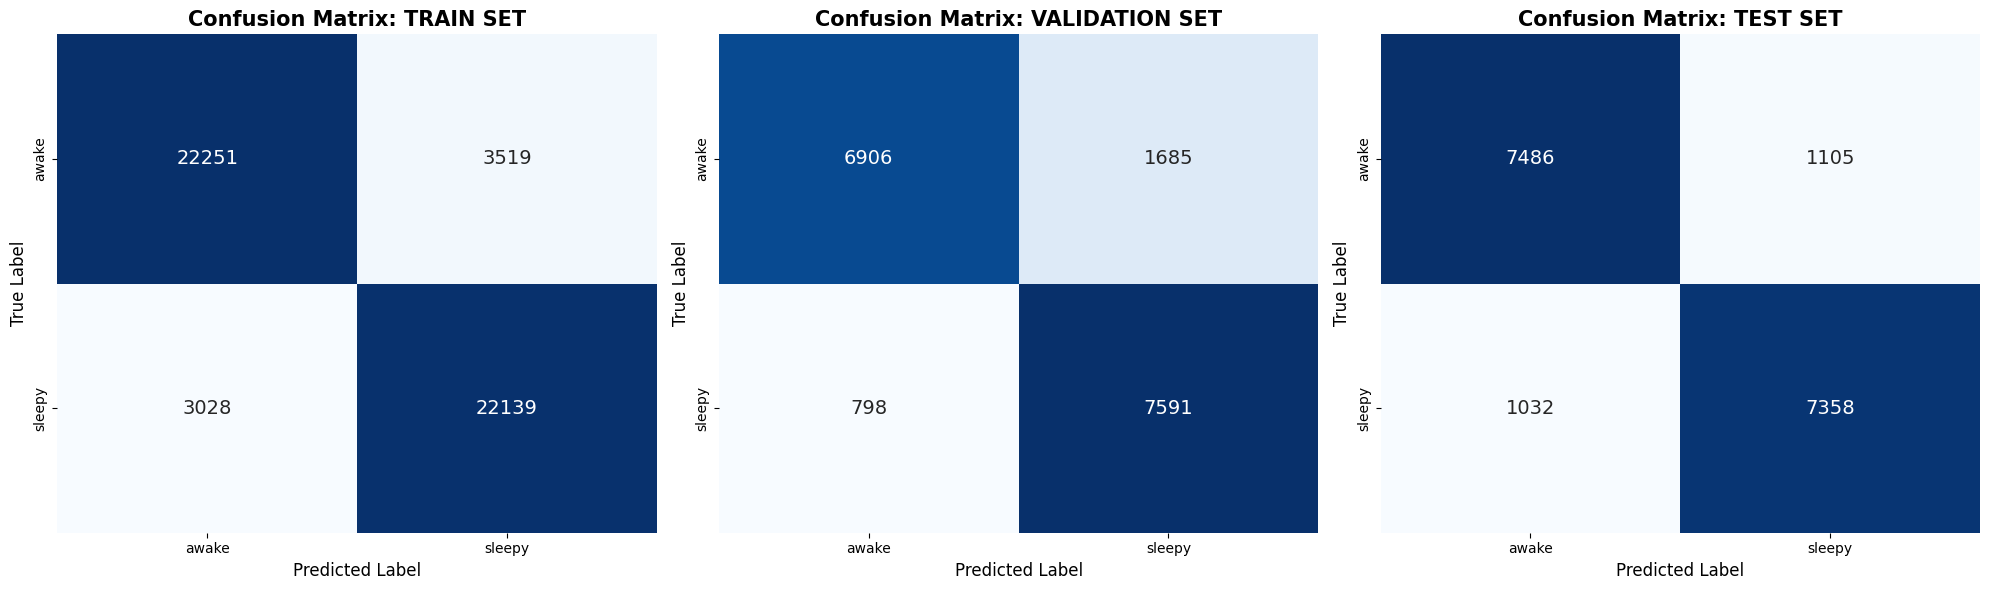

In [ ]:
import matplotlib.pyplot as plt           # Library for creating the actual plot/figure
import seaborn as sns                    # Library for styling the heatmaps to look clean
from sklearn.metrics import confusion_matrix # Function that actually computes the TP, TN, FP, FN values

def plot_final_matrices(model, train_loader, val_loader):
    """
    Generates and plots confusion matrices for all three sets (Train, Val, Test).
    """
    model.eval() # Sets the model to evaluation mode (disables Dropout and BatchNorm)
    
    # 1. Re-establishing the Test Loader
    TEST_PATH = '/kaggle/input/mrl-eye-dataset/data/test' # Defines where your test images are stored
    test_ds = datasets.ImageFolder(root=TEST_PATH, transform=test_tf) # Loads the test images with transforms
    test_loader = DataLoader(test_ds, batch_size=128, shuffle=False, num_workers=4) # Batches the test data for processing
    
    # 2. Setup Plotting
    fig, axes = plt.subplots(1, 3, figsize=(20, 6)) # Creates 1 row with 3 subplots (Train, Val, Test)
    loaders = [train_loader, val_loader, test_loader] # Puts all our data loaders into a list for looping
    titles = ['TRAIN SET', 'VALIDATION SET', 'TEST SET'] # Titles for each of the three matrix plots
    class_names = train_ds.classes # Gets the names of the classes: ['awake', 'sleepy']
    
    print("Generating Matrices... Please wait.") # Status update for the user
    
    for i, loader in enumerate(loaders): # Loop through each dataset one by one
        all_true = [] # List to store the real ground-truth labels
        all_pred = [] # List to store the labels predicted by the model
        
        with torch.no_grad(): # Disables gradient tracking to save memory and speed up inference
            for imgs, labs in tqdm(loader, desc=f"Processing {titles[i]}"): # Loop through batches with a progress bar
                imgs, labs = imgs.to(DEVICE), labs.to(DEVICE) # Move images and labels to the GPU
                out = model(imgs) # Run the images through your MobileNet model
                _, p = torch.max(out, 1) # Get the index (0 or 1) of the highest probability prediction
                all_true.extend(labs.cpu().numpy()) # Move real labels back to CPU and add to our list
                all_pred.extend(p.cpu().numpy()) # Move predicted labels back to CPU and add to our list
        
        # Calculate Matrix
        cm = confusion_matrix(all_true, all_pred) # Compare real vs predicted to build the matrix
        
        # Plotting with Seaborn
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i], # Create heatmap with integer values ('d') and blue color
                    xticklabels=class_names, yticklabels=class_names, # Label the axes with 'awake' and 'sleepy'
                    cbar=False, annot_kws={"size": 14}) # Hide the side color bar and set font size for numbers
        
        axes[i].set_title(f'Confusion Matrix: {titles[i]}', fontsize=15, fontweight='bold') # Set bold title for each subplot
        axes[i].set_xlabel('Predicted Label', fontsize=12) # Label for the horizontal axis
        axes[i].set_ylabel('True Label', fontsize=12) # Label for the vertical axis

    plt.tight_layout() # Automatically adjust spacing so labels don't overlap
    plt.show() # Display the final three-panel plot on the screen

# Run the plotting function
plot_final_matrices(model, train_loader, val_loader) # Execute the logic above

Processing: /kaggle/input/mrl-eye-dataset/data/test/awake/s0001_01850_0_0_1_0_0_01.png


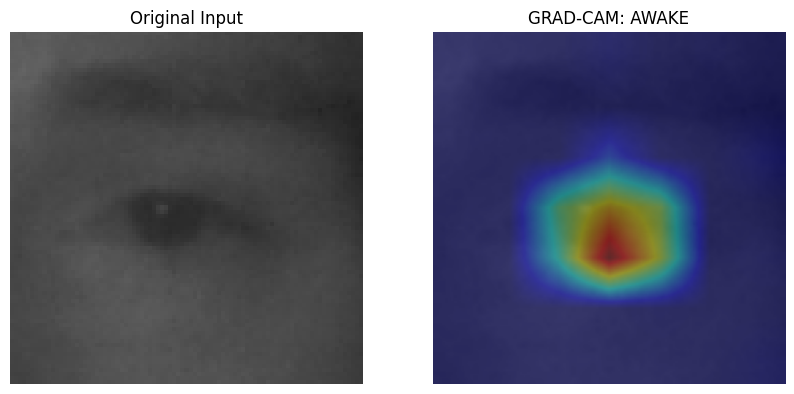

In [ ]:
def show_gradcam(model, image_path, device="cuda"):
    # Access the raw model even if it's wrapped in DataParallel for multi-GPU use
    actual_model = model.module if hasattr(model, 'module') else model
    actual_model.eval() # Set model to evaluation mode (stops training behavior)
    
    # Ensure reproducibility so results are consistent every time you run it
    torch.manual_seed(42)
    np.random.seed(42)

    # Identify the target layer (usually the last convolutional layer) to extract features from
    target_layer = actual_model[0][-1] 
    # Dictionary to store the intermediate math (gradients and feature maps)
    data = {"gradients": None, "activations": None}
    
    # Function to capture gradients during the "backward" pass
    def save_gradient(module, grad_input, grad_output):
        data["gradients"] = grad_output[0].detach() 
        
    # Function to capture feature maps (activations) during the "forward" pass
    def save_activation(module, input, output):
        data["activations"] = output.detach()
        
    # Attach "hooks" to the target layer so it automatically saves data when the model runs
    h1 = target_layer.register_forward_hook(save_activation)
    h2 = target_layer.register_full_backward_hook(save_gradient)
    
    # Try to open the image; if it fails, clean up the hooks and stop
    try:
        img_pil = Image.open(image_path).convert('RGB')
    except Exception as e:
        print(f"Error: Could not find image at {image_path}")
        h1.remove(); h2.remove()
        return

    # Transform image for the model and add a batch dimension (1, C, H, W)
    img_tensor = val_tf(img_pil).unsqueeze(0).to(device)
    img_tensor.requires_grad = True # Enable gradient tracking on the image itself
    
    actual_model.zero_grad() # Clear any old gradients from memory
    logits = actual_model(img_tensor) # Forward pass: get the model's prediction
    class_idx = logits.argmax(dim=1).item() # Find the predicted class (Awake or Sleepy)
    logits[0, class_idx].backward() # Backward pass: calculate importance of each pixel for that class
    
    gradients = data["gradients"] # Retrieve the saved gradients
    activations = data["activations"] # Retrieve the saved feature maps
    
    # Global Average Pooling: Calculate the importance "weight" of each feature map
    weights = torch.mean(gradients, dim=[2, 3]) 
    
    # Create the Class Activation Map (CAM) by multiplying weights by activations
    cam = torch.zeros(activations.shape[2:], dtype=torch.float32, device=device)
    for i, w in enumerate(weights[0]):
        cam += w * activations[0, i, :, :]
    
    # Process the heatmap: convert to CPU and remove negative values (ReLU)
    heatmap = cam.cpu().numpy()
    heatmap = np.maximum(heatmap, 0)
    heatmap /= (np.max(heatmap) + 1e-8) # Normalize between 0 and 1
    
    # Clean up: remove the hooks so they don't slow down future model usage
    h1.remove(); h2.remove()
    
    # Convert original image to OpenCV format (BGR) for color mapping
    img_cv = cv2.cvtColor(np.array(img_pil), cv2.COLOR_RGB2BGR)
    img_cv = cv2.resize(img_cv, (224, 224)) # Resize to match model input
    heatmap_res = cv2.resize(heatmap, (224, 224)) # Resize heatmap to match image size
    
    # Apply a "Jet" colormap (Red = Hot/Important, Blue = Cold/Irrelevant)
    heatmap_col = cv2.applyColorMap(np.uint8(255 * heatmap_res), cv2.COLORMAP_JET)
    # Overlay the heatmap on the original eye image with 40% transparency
    overlay = cv2.addWeighted(img_cv, 0.6, heatmap_col, 0.4, 0) 
    
    # Plot the results side-by-side
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(img_pil)
    plt.title("Original Input")
    plt.axis('off')
    
    plt.subplot(1, 2, 2)
    class_name = train_ds.classes[class_idx].upper()
    plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    plt.title(f"GRAD-CAM: {class_name}") 
    plt.axis('off')
    plt.show()

Processing: /kaggle/input/mrl-eye-dataset/data/test/sleepy/s0001_00126_0_0_0_0_0_01.png


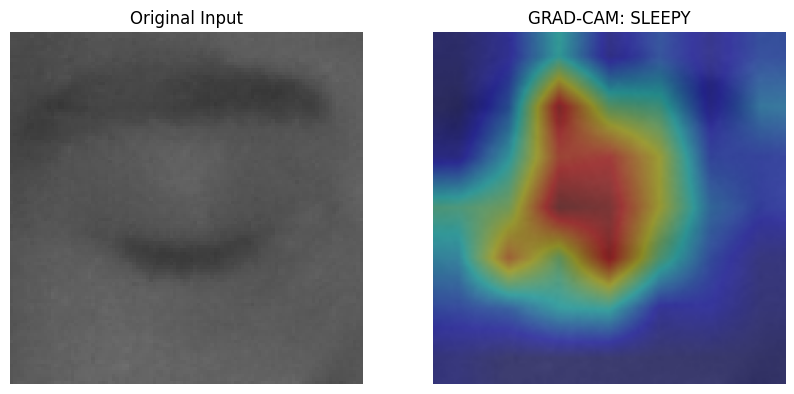

In [ ]:
def show_gradcam(model, image_path, device="cuda"):
    # Access the base model (unwraps it if you used DataParallel for multiple GPUs)
    actual_model = model.module if hasattr(model, 'module') else model
    actual_model.eval() # Set model to evaluation mode (freezes BatchNorm/Dropout)
    
    # Set seeds to ensure the heatmap generation is consistent across runs
    torch.manual_seed(42)
    np.random.seed(42)

    # Pick the target layer (actual_model[0][-1] is the last conv layer in your MobileNet)
    target_layer = actual_model[0][-1] 
    # Create a storage container for the gradients and feature map activations
    data = {"gradients": None, "activations": None}
    
    # Helper to capture gradients flowing back through the target layer
    def save_gradient(module, grad_input, grad_output):
        data["gradients"] = grad_output[0].detach() 
        
    # Helper to capture the feature maps generated during the forward pass
    def save_activation(module, input, output):
        data["activations"] = output.detach()
        
    # Register "hooks" so the model automatically calls these helpers during the run
    h1 = target_layer.register_forward_hook(save_activation)
    h2 = target_layer.register_full_backward_hook(save_gradient)
    
    try:
        # Load image and ensure it is in 3-channel RGB format
        img_pil = Image.open(image_path).convert('RGB')
    except Exception as e:
        print(f"Error: Could not find image at {image_path}")
        h1.remove(); h2.remove()
        return

    # Preprocess image (resize/normalize) and add batch dimension [1, 3, 224, 224]
    img_tensor = val_tf(img_pil).unsqueeze(0).to(device)
    img_tensor.requires_grad = True # Allow us to compute gradients relative to the image
    
    actual_model.zero_grad() # Reset any existing gradients in the model
    logits = actual_model(img_tensor) # Forward pass: get the model's raw scores
    class_idx = logits.argmax(dim=1).item() # Determine which class the model predicted
    logits[0, class_idx].backward() # Backward pass: calculate importance of features for that class
    
    gradients = data["gradients"] # Extract the captured gradients
    activations = data["activations"] # Extract the captured feature maps
    
    # Global Average Pooling: Compress gradients into a single "importance weight" per channel
    weights = torch.mean(gradients, dim=[2, 3]) 
    
    # Initialize an empty canvas for the Class Activation Map (CAM)
    cam = torch.zeros(activations.shape[2:], dtype=torch.float32, device=device)
    # Multiply each feature map by its calculated weight and sum them up
    for i, w in enumerate(weights[0]):
        cam += w * activations[0, i, :, :]
    
    # Post-processing: remove negative values (ReLU logic) and normalize to 0-1 scale
    heatmap = cam.cpu().numpy()
    heatmap = np.maximum(heatmap, 0)
    heatmap /= (np.max(heatmap) + 1e-8) 
    
    # CRITICAL: Remove hooks to prevent memory leaks and interference in future runs
    h1.remove(); h2.remove()
    
    # Convert original image to OpenCV format and resize for visualization
    img_cv = cv2.cvtColor(np.array(img_pil), cv2.COLOR_RGB2BGR)
    img_cv = cv2.resize(img_cv, (224, 224))
    heatmap_res = cv2.resize(heatmap, (224, 224)) # Resize heatmap to match image size
    
    # Apply a color map (JET: Blue is cold/irrelevant, Red is hot/important)
    heatmap_col = cv2.applyColorMap(np.uint8(255 * heatmap_res), cv2.COLORMAP_JET)
    # Blend the original image (60% weight) with the heatmap (40% weight)
    overlay = cv2.addWeighted(img_cv, 0.6, heatmap_col, 0.4, 0) 
    
    # Plotting code to show the "Before" (Original) and "After" (Explainability)
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(img_pil)
    plt.title("Original Input")
    plt.axis('off')
    
    plt.subplot(1, 2, 2)
    class_name = train_ds.classes[class_idx].upper()
    plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    plt.title(f"GRAD-CAM: {class_name}") 
    plt.axis('off')
    plt.show()


📄 FINAL REPORT SELECTION: SAMPLE #8
📁 File: s0021_00852_0_1_1_1_0_01.png


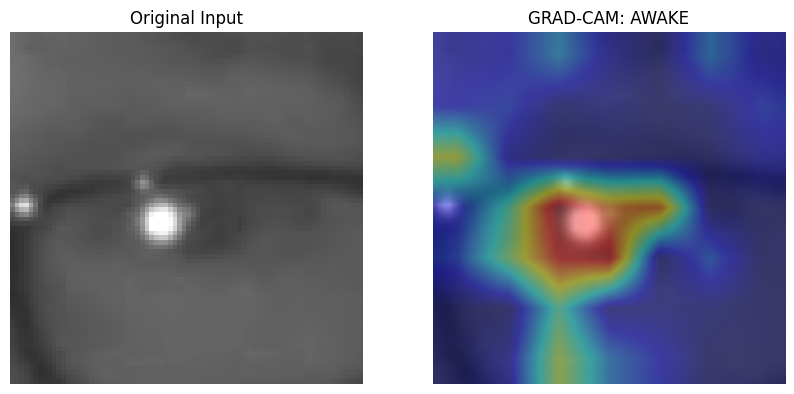

In [23]:
# ==========================================================
# FINAL REPORT: TARGET SAMPLE #8
# ==========================================================
if 'final_list' in locals() and len(final_list) >= 8:
    target_path = final_list[7] # Index 7 is the 8th image
    
    print(f"\n{'='*40}")
    print(f"📄 FINAL REPORT SELECTION: SAMPLE #8")
    print(f"📁 File: {os.path.basename(target_path)}")
    print(f"{'='*40}")
    
    try:
        # Generate the final heatmap for your project documentation
        show_gradcam(model, target_path)
    except Exception as e:
        print(f"❌ Grad-CAM failed: {e}")
else:
    print("❌ Error: 'final_list' doesn't have 8 images. Run the search cell first!")

In [ ]:
import torch

# Save the state_dict (learned weights)
# This is the industry standard for PyTorch
torch.save(model.state_dict(), "eye_model_weights.pth")

print("Model saved as eye_model_weights.pth")

In [ ]:
print(train_ds.class_to_idx)

In [ ]:
!pip install timm

In [ ]:
import os # Helps talk to your folders
import time # Used to track how long training takes
import torch # The main engine for the deep learning
import nn as nn # The tool for building neural network layers
import optim as optim # The engine for updating model weights
try:
    import pretrainedmodels # External library with the NASNet architecture
except ImportError:
    !pip install pretrainedmodels # Downloads the library if Kaggle doesn't have it
    import pretrainedmodels
from torchvision import datasets, transforms # Tools for handling images
from torch.utils.data import DataLoader # Tool for batching images
from tqdm.auto import tqdm # The progress bar library
from sklearn.metrics import accuracy_score, classification_report # For the final scorecards

# ===============================
# 0. SETTINGS
# ===============================
DEVICE = "cuda" if torch.cuda.is_available() else "cpu" # Uses the GPU if available, else CPU
BASE_PATH = '/kaggle/input/mrl-eye-dataset/data' # Where your eye images live
SEED = 42 # Keeps the randomness consistent for every run
torch.manual_seed(SEED) # Sets the seed for PyTorch

# ===============================
# 1. DATA PIPELINE
# ===============================
data_tf = transforms.Compose([
    transforms.Resize((224, 224)), # Squishes images to 224x224 pixels
    transforms.Grayscale(num_output_channels=3), # Turns gray images into 3-channel RGB
    transforms.ToTensor(), # Converts pixels into math tensors
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]) # Centers data around zero
])

train_ds = datasets.ImageFolder(os.path.join(BASE_PATH, 'train'), transform=data_tf) # Loads training images
val_ds   = datasets.ImageFolder(os.path.join(BASE_PATH, 'val'), transform=data_tf) # Loads validation images
test_ds  = datasets.ImageFolder(os.path.join(BASE_PATH, 'test'), transform=data_tf) # Loads test images

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2) # Batches train data randomly
val_loader   = DataLoader(val_ds,   batch_size=32, shuffle=False) # Batches val data in order
test_loader  = DataLoader(test_ds,  batch_size=32, shuffle=False) # Batches test data in order

# ===============================
# 2. ARCHITECTURE
# ===============================
print(f"Building NASNet-Mobile Architecture with p=0.55 Dropout...") # Status message
model_name = 'nasnetamobile' # String name for the model
model = pretrainedmodels.__dict__[model_name](num_classes=1000, pretrained='imagenet') # Downloads pre-trained NASNet

in_features = model.last_linear.in_features # Counts how many inputs go into the final layer

model.last_linear = nn.Sequential(
    nn.Dropout(p=0.55), # Kills 55% of neurons randomly to stop overfitting
    nn.Linear(in_features, 2) # Final layer outputs scores for 2 classes (awake/sleepy)
)

model = model.to(DEVICE) # Sends the model to the GPU memory

optimizer = optim.Adam(model.parameters(), lr=1e-7) # Updates weights with a tiny step size
criterion = nn.CrossEntropyLoss() # Measures the error between prediction and reality

# ===============================
# 3. EVALUATION HELPER
# ===============================
def quick_eval(loader):
    model.eval() # Stops dropout and sets model to testing mode
    correct = 0 # Counter for right guesses
    total = 0 # Counter for total images
    with torch.no_grad(): # Disables gradient math to save memory
        for imgs, labs in loader: # Loops through data
            imgs, labs = imgs.to(DEVICE), labs.to(DEVICE) # Sends data to GPU
            out = model(imgs) # Model makes its prediction
            _, p = torch.max(out, 1) # Picks the class with the highest score
            total += labs.size(0) # Updates total count
            correct += (p == labs).sum().item() # Updates correct count
    return correct / total # Returns decimal accuracy

# ===============================
# 4. TRAINING WITH EPOCH AUDIT
# ===============================
def run_full_training(epochs=6):
    start_time = time.time() # Records start time
    
    print("\n" + "=" * 30) # Formatting line
    print("STARTING TRAINING AUDIT") # Header
    print("=" * 30 + "\n") # Formatting line

    for epoch in range(epochs): # Main training loop
        model.train() # Activates training mode and dropout
        train_loss = 0.0 # Resets loss counter for the epoch
        loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}", leave=True) # Progress bar
        
        for imgs, labs in loop: # Loop through training batches
            imgs, labs = imgs.to(DEVICE), labs.to(DEVICE) # Move batch to GPU
            optimizer.zero_grad() # Clears old gradients from the last batch
            out = model(imgs) # Forward pass: get predictions
            loss = criterion(out, labs) # Calculate how wrong the model was
            loss.backward() # Backward pass: find which weights caused the error
            optimizer.step() # Update weights to reduce future error
            train_loss += loss.item() # Accumulate loss value

        t_acc = quick_eval(train_loader) # Check training accuracy after epoch
        v_acc = quick_eval(val_loader) # Check validation accuracy after epoch
        avg_loss = train_loss / len(train_loader) # Calculate average loss per batch
        
        print(f" Epoch {epoch+1}: Loss: {avg_loss:.4f} | Train Acc: {t_acc:.4f} | Val Acc: {v_acc:.4f}") # Print status

    # ===============================
    # 5. FINAL TRIPLE REPORT
    # ===============================
    def get_final_report(loader, name):
        model.eval() # Ensure model is in eval mode
        y_true, y_pred = [], [] # Lists for real and predicted values
        with torch.no_grad(): # No math tracking needed
            for imgs, labs in loader: # Loop through the loader
                imgs, labs = imgs.to(DEVICE), labs.to(DEVICE) # To GPU
                out = model(imgs) # Get outputs
                _, p = torch.max(out, 1) # Get predicted index
                y_true.extend(labs.cpu().numpy()) # Save real labels to list
                y_pred.extend(p.cpu().numpy()) # Save predicted labels to list
        print(f"\n[FINAL REPORT: {name} SET]") # Print set name
        print(classification_report(y_true, y_pred, target_names=train_ds.classes)) # Print F1/Precision/Recall
        return accuracy_score(y_true, y_pred) # Return final accuracy number

    print("\n" + "█"*60) # Visual separator
    print("             OFFICIAL NASNET-MOBILE FINAL AUDIT") # Header
    print("█"*60) # Visual separator

    _ = get_final_report(train_loader, "TRAINING") # Run final report on train set
    _ = get_final_report(val_loader, "VALIDATION") # Run final report on val set
    final_test_acc = get_final_report(test_loader, "TEST") # Run final report on test set

    total_time = time.time() - start_time # Calculate total duration
    print("█"*60) # Visual separator
    print(f"TOTAL TIME: {total_time:.2f}s") # Print total seconds
    print("█"*60) # Visual separator

# Run it!
run_full_training(epochs=6) # Call the function to start everything

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 kB 1.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for pretrainedmodels: filename=pretrainedmodels-0.7.4-py3-none-any.whl size=60945 sha256=3117b15c30a4233850958630ed28948f1f000047d1d3ab49673b5a3defbf767d
  Stored in directory: /root/.cache/pip/wheels/4c/01/56/40a48f75dbdfe167a0cb70d3b48913369a00ec5c4e9fed5f2b
Successfully built pretrainedmodels
Building NASNet-Mobile Architecture with p=0.55 Dropout...
Downloading: "http://data.lip6.fr/cadene/pretrainedmodels/nasnetamobile-7e03cead.pth" to /root/.cache/torch/hub/checkpoints/nasnetamobile-7e03cead.pth


100%|██████████| 20.5M/20.5M [00:01<00:00, 15.3MB/s]



STARTING TRAINING AUDIT



Epoch 1/6:   0%|          | 0/1592 [00:00<?, ?it/s]

 Epoch 1: Loss: 0.7672 | Train Acc: 0.5317 | Val Acc: 0.5329


...

 Epoch 4: Loss: 0.6646 | Train Acc: 0.7738 | Val Acc: 0.7723


Epoch 5/6:   0%|          | 0/1592 [00:00<?, ?it/s]

 Epoch 5: Loss: 0.6358 | Train Acc: 0.8112 | Val Acc: 0.8115


Epoch 6/6:   0%|          | 0/1592 [00:00<?, ?it/s]

 Epoch 6: Loss: 0.6062 | Train Acc: 0.8365 | Val Acc: 0.8363

████████████████████████████████████████████████████████████
             OFFICIAL NASNET-MOBILE FINAL AUDIT
████████████████████████████████████████████████████████████

[FINAL REPORT: TRAINING SET]
              precision    recall  f1-score   support

       awake       0.81      0.88      0.84     25770
      sleepy       0.86      0.79      0.83     25167

    accuracy                           0.84     50937
   macro avg       0.84      0.84      0.84     50937
weighted avg       0.84      0.84      0.84     50937


[FINAL REPORT: VALIDATION SET]
              precision    recall  f1-score   support

       awake       0.81      0.88      0.84      8591
      sleepy       0.86      0.80      0.83      8389

    accuracy                           0.84     16980
   macro avg       0.84      0.84      0.84     16980
weighted avg       0.84      0.84      0.84     16980


[FINAL REPORT: TEST SET]
              precision   

Generating Matrices... Please wait.


Processing TRAIN SET:   0%|          | 0/1592 [00:00<?, ?it/s]

Processing VALIDATION SET:   0%|          | 0/531 [00:00<?, ?it/s]

Processing TEST SET:   0%|          | 0/531 [00:00<?, ?it/s]

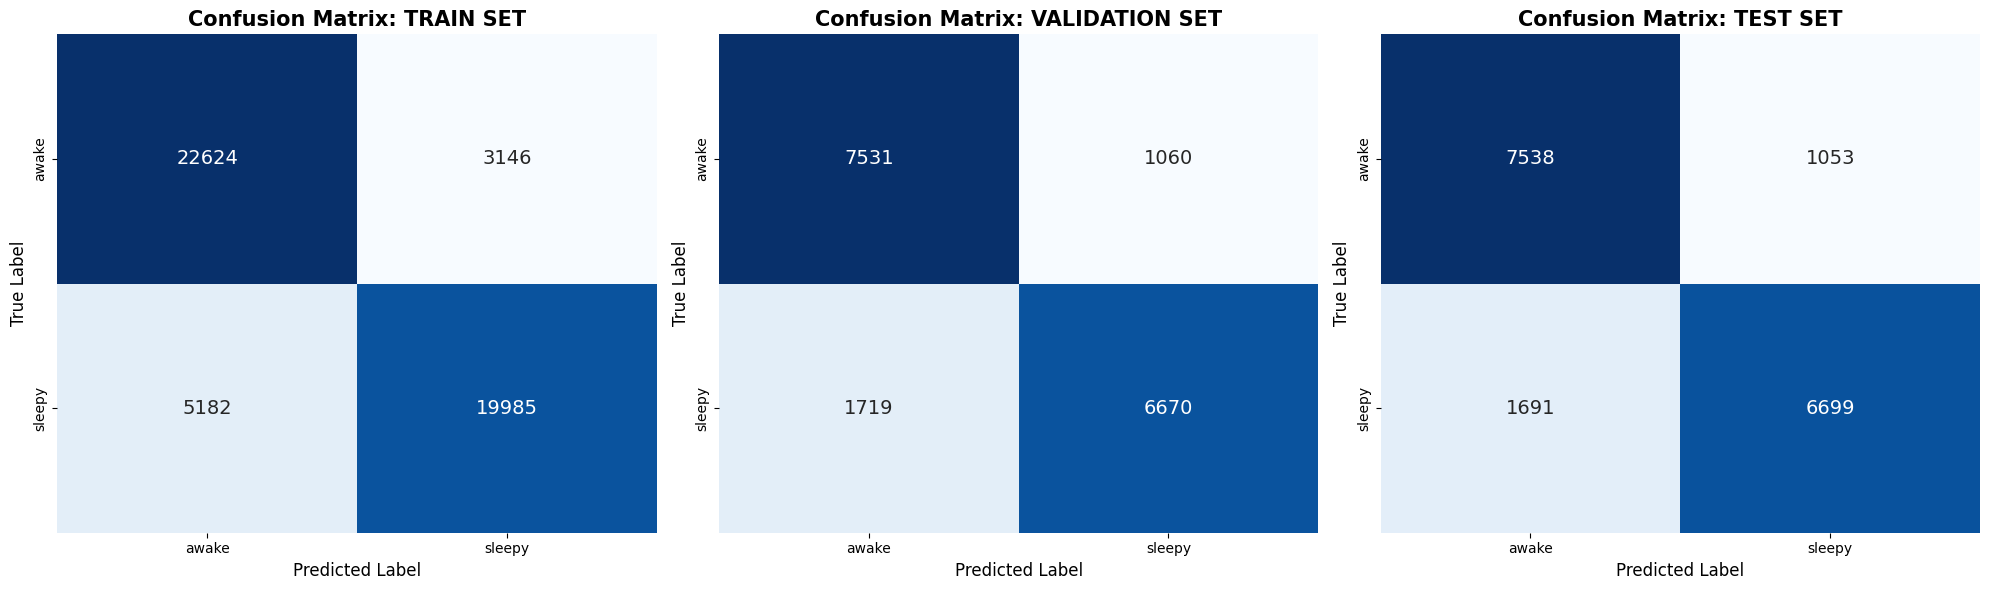

In [ ]:
import matplotlib.pyplot as plt           # Library for generating the final plot figures
import seaborn as sns                    # Tool for making the heatmaps look professional
from sklearn.metrics import confusion_matrix # Function that calculates the actual TP, TN, FP, FN counts

def plot_final_matrices(model, train_loader, val_loader, test_loader):
    """
    Generates and plots confusion matrices for all three sets in a single row.
    """
    model.eval() # Sets the model to evaluation mode to turn off dropout
    
    # 1. Setup Plotting for 1x3 Grid
    fig, axes = plt.subplots(1, 3, figsize=(20, 6)) # Creates one row with three side-by-side plots
    loaders = [train_loader, val_loader, test_loader] # Puts all data sources into a single list
    titles = ['TRAIN SET', 'VALIDATION SET', 'TEST SET'] # Titles for each of the three charts
    class_names = train_ds.classes  # Gets the labels ['awake', 'sleepy'] from the dataset

    print("Generating Matrices... Please wait.") # Simple status update for the console
    
    for i, loader in enumerate(loaders): # Loop through each dataset (Train, then Val, then Test)
        # Force workers to 0 to avoid the 'can only test a child process' error
        loader.num_workers = 0 # Ensures the data loading happens in the main process to prevent crashes
        
        all_true = [] # List to store the actual ground-truth labels from the dataset
        all_pred = [] # List to store the predictions made by your model
        
        with torch.no_grad(): # Disables gradient math to save GPU memory and increase speed
            for imgs, labs in tqdm(loader, desc=f"Processing {titles[i]}", leave=False): # Loop through image batches
                imgs, labs = imgs.to(DEVICE), labs.to(DEVICE) # Push images and labels to the GPU
                out = model(imgs) # Run the images through the model to get raw scores
                _, p = torch.max(out, 1) # Pick the index (0 or 1) with the highest score
                all_true.extend(labs.cpu().numpy()) # Move real labels to CPU and save to list
                all_pred.extend(p.cpu().numpy()) # Move predicted labels to CPU and save to list
        
        # 2. Calculate Matrix
        cm = confusion_matrix(all_true, all_pred) # Build the square matrix comparing real vs predicted
        
        # 3. Plotting with Seaborn Heatmap
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i], # Create blue heatmap with decimal integers
                    xticklabels=class_names, yticklabels=class_names, # Label the X and Y axes with awake/sleepy
                    cbar=False, annot_kws={"size": 14}) # Hide the side color bar and set text size
        
        axes[i].set_title(f'Confusion Matrix: {titles[i]}', fontsize=15, fontweight='bold') # Set a bold title for the subplot
        axes[i].set_xlabel('Predicted Label', fontsize=12) # Label for the horizontal axis
        axes[i].set_ylabel('True Label', fontsize=12) # Label for the vertical axis

    plt.tight_layout() # Adjust the padding between subplots so they don't overlap
    plt.show() # Display the final three-panel figure

# Run the plotting function using your already trained model
plot_final_matrices(model, train_loader, val_loader, test_loader) # Execute the function to see the results

In [3]:
# ===============================
# 6. SAVE THE MODEL
# ===============================
SAVE_DIR = "models"
os.makedirs(SAVE_DIR, exist_ok=True)

# Path to save the weights
model_save_path = os.path.join(SAVE_DIR, "nasnet_mobile_drowsiness.pth")

# Save the state_dict
torch.save(model.state_dict(), model_save_path)

print(f"✅ Model weights successfully saved to: {model_save_path}")

✅ Model weights successfully saved to: models/nasnet_mobile_drowsiness.pth


In [ ]:
import torch # The main math and neural network engine
import torch.nn as nn # Used for defining the layers of the model
from PIL import Image # Library used for opening and handling image files
import os # Standard library for interacting with the operating system paths
try:
    import pretrainedmodels # External library containing the NASNet architecture
except ImportError:
    !pip install pretrainedmodels # Installs the library if it is missing
    import pretrainedmodels

# ===============================
# 1. INITIALIZE ARCHITECTURE
# ===============================
model_name = 'nasnetamobile' # String name of the specific model to build
model = pretrainedmodels.__dict__[model_name](num_classes=1000, pretrained=None) # Creates the empty NASNet structure
in_features = model.last_linear.in_features # Finds the size of the feature vector before the final layer

# Re-builds the final layers exactly as they were during training (Dropout + Linear)
model.last_linear = nn.Sequential(
    nn.Dropout(p=0.55), # Sets the same 55% dropout used in training
    nn.Linear(in_features, 2) # Final layer to output 2 classes (awake vs sleepy)
)

# ===============================
# 2. LOAD SAVED WEIGHTS
# ===============================
MODEL_PATH = '/kaggle/working/models/nasnet_mobile_drowsiness.pth' # Path to your saved .pth file
DEVICE = "cuda" if torch.cuda.is_available() else "cpu" # Checks for GPU availability

# Loads the learned weights (state_dict) into the empty model structure
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model = model.to(DEVICE) # Sends the model weights to the GPU or CPU
model.eval() # Puts model in evaluation mode (important for freezing Dropout)
print(f"Model loaded successfully from {MODEL_PATH}") # Confirmation message

# ===============================
# 3. RUN PREDICTION
# ===============================
img_path = '/kaggle/input/mrl-eye-dataset/data/test/sleepy/s0001_00001_0_0_0_0_0_01.png' # Path to the specific image to test
img = Image.open(img_path) # Opens the image file from the path

# Applies the same Resize/Normalize transforms used in training and adds batch dimension
input_tensor = data_tf(img).unsqueeze(0).to(DEVICE) 

with torch.no_grad(): # Disables gradient tracking to make prediction faster and save memory
    output = model(input_tensor) # Passes the image through the network to get raw scores
    _, predicted = torch.max(output, 1) # Finds the index of the highest score (the prediction)

# Mapping the index back to a human-readable name
class_names = ['open', 'sleepy'] # List of classes matching your training folders
prediction = class_names[predicted.item()] # Gets the final text result

print(f"\nTarget Image: {img_path}") # Prints the image path for reference
print(f"Result: {prediction}") # Prints the final prediction (Open or Sleepy)

✅ Model loaded successfully from /kaggle/working/models/nasnet_mobile_drowsiness.pth

Target Image: /kaggle/input/mrl-eye-dataset/data/test/sleepy/s0001_00001_0_0_0_0_0_01.png
Result: sleepy ✅


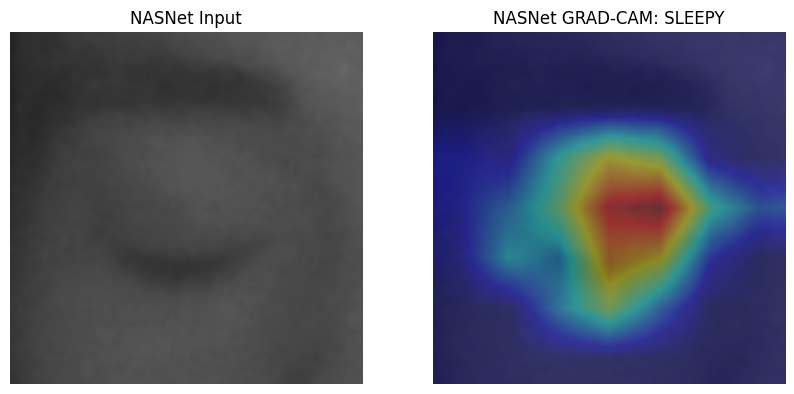

In [ ]:
import cv2 # OpenCV for image processing and colormaps
import numpy as np # For numerical operations on the heatmap
import matplotlib.pyplot as plt # For displaying the final side-by-side plots
from PIL import Image # For opening the image files correctly
import torch # The core deep learning framework
import torch.nn as nn # Used for checking layer types (Conv2d)
import torch.nn.functional as F # Used for mathematical operations
import os # For checking if files exist

# ===============================
# NASNET-MOBILE STABILIZED GRAD-CAM
# ===============================
def show_nasnet_gradcam(model, image_path, device="cuda"):
    # Access the base model (unwraps DataParallel if used)
    actual_model = model.module if hasattr(model, 'module') else model
    actual_model.eval() # Sets model to evaluation mode
    
    # Keeps results identical every time you run the script
    torch.manual_seed(42)
    np.random.seed(42)

    # Gets a dictionary of every layer inside NASNet
    model_dict = dict(actual_model.named_modules())
    # Targets 'cell_11', which is the deepest feature-heavy part of NASNet-Mobile
    target_layer = model_dict.get('cell_11')
    
    if target_layer is None:
        # Emergency backup: if 'cell_11' isn't found, find the last convolution layer
        for name, module in actual_model.named_modules():
            if isinstance(module, nn.Conv2d):
                target_layer = module
    
    # Container for the gradients and feature activations
    data = {"gradients": None, "activations": None}
    
    # Saves the error signals during the backward pass
    def save_gradient(module, grad_input, grad_output):
        data["gradients"] = grad_output[0].detach() 
        
    # Saves the visual features during the forward pass
    def save_activation(module, input, output):
        data["activations"] = output.detach()
        
    # Attaches the functions above to the target layer
    h1 = target_layer.register_forward_hook(save_activation)
    h2 = target_layer.register_full_backward_hook(save_gradient)
    
    try:
        # Load the eye image and ensure it has 3 channels
        img_pil = Image.open(image_path).convert('RGB')
    except Exception as e:
        print(f"Error: Could not find image at {image_path}")
        h1.remove(); h2.remove()
        return

    # Prepare image for the model (Resize, Normalize, and add batch dimension)
    img_tensor = data_tf(img_pil).unsqueeze(0).to(device)
    img_tensor.requires_grad = True # Enable math tracking for the image pixels
    
    actual_model.zero_grad() # Reset old gradients
    logits = actual_model(img_tensor) # Get the model's prediction scores
    class_idx = logits.argmax(dim=1).item() # Pick the highest score (awake or sleepy)
    logits[0, class_idx].backward() # Backpropagate to see which pixels mattered
    
    gradients = data["gradients"] # Get the saved gradients
    activations = data["activations"] # Get the saved feature maps
    
    # Calculate weights by averaging gradients across the feature map
    weights = torch.mean(gradients, dim=[2, 3]) 
    
    # Initialize the heatmap canvas
    cam = torch.zeros(activations.shape[2:], dtype=torch.float32, device=device)
    # Combine feature maps multiplied by their importance weights
    for i, w in enumerate(weights[0]):
        cam += w * activations[0, i, :, :]
    
    # Move heatmap to CPU, remove negative values, and scale to 0-1
    heatmap = cam.cpu().numpy()
    heatmap = np.maximum(heatmap, 0)
    heatmap /= (np.max(heatmap) + 1e-8)
    
    # Remove the hooks so they don't interfere with the model later
    h1.remove(); h2.remove()
    
    # Prepare original image for display using OpenCV
    img_cv = cv2.cvtColor(np.array(img_pil), cv2.COLOR_RGB2BGR)
    img_cv = cv2.resize(img_cv, (224, 224)) # Match model input size
    heatmap_res = cv2.resize(heatmap, (224, 224)) # Match image size
    
    # Create a color version of the heatmap (Red = Hot, Blue = Cold)
    heatmap_col = cv2.applyColorMap(np.uint8(255 * heatmap_res), cv2.COLORMAP_JET)
    # Blend the image (60%) with the heatmap (40%)
    overlay = cv2.addWeighted(img_cv, 0.6, heatmap_col, 0.4, 0) 
    
    # Final plot setup
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1) # Left side
    plt.imshow(cv2.cvtColor(img_cv, cv2.COLOR_BGR2RGB))
    plt.title("NASNet Input")
    plt.axis('off')
    
    plt.subplot(1, 2, 2) # Right side
    class_name = train_ds.classes[class_idx].upper() # Get prediction name
    plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    plt.title(f"NASNet GRAD-CAM: {class_name}") 
    plt.axis('off')
    plt.show() # Display everything

# Execute the code on a specific sleepy eye image
sample_path = '/kaggle/input/mrl-eye-dataset/data/test/sleepy/s0001_00001_0_0_0_0_0_01.png'
if os.path.exists(sample_path):
    print(f"Processing: {sample_path}")
    show_nasnet_gradcam(model, sample_path)

Executing Grad-CAM analysis for sample: s0037_03492_1_1_0_0_0_01.png


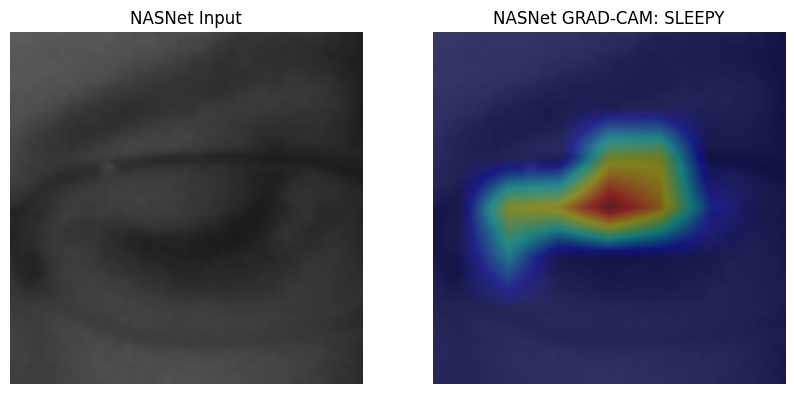

In [6]:
# Specifically targeting the primary successful test case
target_file = 's0037_03492_1_1_0_0_0_01.png'
target_path = os.path.join('/kaggle/input/mrl-eye-dataset/data/test/sleepy/', target_file)

if os.path.exists(target_path):
    print(f"Executing Grad-CAM analysis for sample: {target_file}")
    show_nasnet_gradcam(model, target_path)
else:
    print("Execution failed: File path not found in the specified directory.")

BEEP BEEP: s0001_01885_0_0_1_0_0_01.png


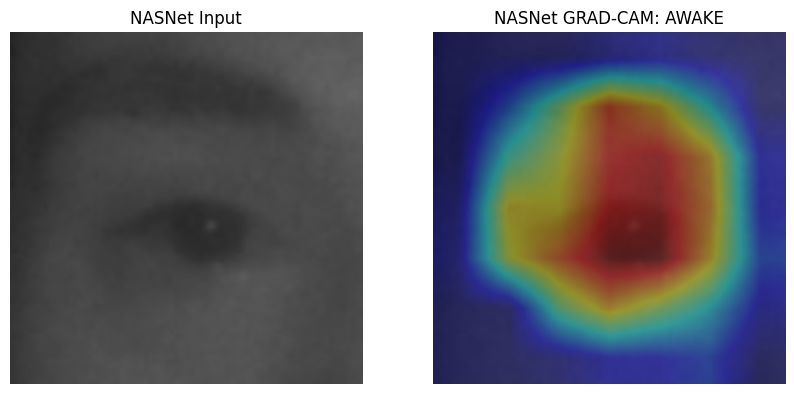

In [14]:
# ==========================================
# GRAD CAM 
# ==========================================
import os

FOLDER = "/kaggle/input/mrl-eye-dataset/data/test/awake/"
# Sorting so it stays the same 10th one 
STUFF = sorted([f for f in os.listdir(FOLDER) if f.endswith('.png')])

MY_PIC = STUFF[9] # Number 10 is index 9 because counting is hard
PATH = os.path.join(FOLDER, MY_PIC)

if os.path.exists(PATH):
    print(f"BEEP BEEP: {MY_PIC}")
    model.eval()
    show_nasnet_gradcam(model, PATH)
else:
    print("Oh no it's gone!!")